# 00 · A complete TTC4TS prediction on CPU
**Purpose:** understand the API and leakage boundaries without downloading models.
This notebook fits lightweight adapters and a Risk regressor around a frozen seasonal-naive
backbone. The generated sine/cosine series and its scores are **synthetic demonstrations**, not paper evidence.
Install `pip install -e ".[analysis,notebooks]"` from the repository and run all cells.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


In [2]:
import torch
import warnings
# Reference InstanceNorm intentionally normalizes 2D hidden activations.
# Suppress only its known feature-count warning to keep outputs portable.
warnings.filterwarnings('ignore', message="input's size at dim=0 does not match num_features", category=UserWarning)
from ttc4ts.adapters import fit_adapters
from ttc4ts.aggregators import LearnedAggregator, errors, features
from ttc4ts.backbones import SeasonalNaive, state_digest
from ttc4ts.generators import Generator
from ttc4ts.predictor import TTC4TS
from ttc4ts.retrieval import RetrievalBank
torch.set_num_threads(2)
torch.manual_seed(7)
context, horizon, fitting_end = 64, 16, 480
t = torch.arange(1100, dtype=torch.float32)
raw = torch.stack([torch.sin(t/8), torch.cos(t/13)+.0005*t], -1) + .05*torch.randn(1100, 2)
data = (raw-raw[:fitting_end].mean(0))/raw[:fitting_end].std(0, unbiased=False).clamp_min(1e-6)
def windows(origins):
    return (torch.stack([data[o-context:o] for o in origins]),
            torch.stack([data[o:o+horizon] for o in origins]))
backbone = SeasonalNaive(period=24)
before = state_digest(backbone)
x, y = windows(torch.arange(96, 400, 32))
adapters, trace = fit_adapters(backbone, x, y, steps=2, hidden_dim=16,
                               max_delta=.3, num_samples=5, seed=7)
bank = RetrievalBank(data, fitting_end, horizon, past=32, stride=8)
generator = Generator(backbone, adapters, bank, seed=7)
print('Adapter Delta:', adapters.deltas.detach().cpu().flatten().tolist())


Adapter Delta: [0.0, 0.07500000298023224, 0.15000000596046448, 0.22499999403953552, 0.30000001192092896]


The aggregator fits on later observed windows. Its historical losses use the already
observed horizon immediately preceding each origin. No current future is used at deployment.
Five deltas produce twelve nonzero Adapter candidates; the toy pool still contains all
twelve augmentations and ten Retrieval-demo candidates.


In [3]:
origins = torch.arange(560, 800, 32)
x, y = windows(origins)
candidates, _ = generator.predict(x, origins, horizon)
previous, _ = generator.predict(windows(origins-horizon)[0], origins-horizon, horizon)
observed = torch.stack([data[o-horizon:o] for o in origins])
feats = features(x, candidates, errors(previous, observed))
risk = LearnedAggregator(candidates.shape[1], mode='risk')
risk.fit(candidates, feats, y, epochs=10, seed=7)
predictor = TTC4TS(generator, context, horizon, mode='risk', aggregator=risk)
origin = 960
result = predictor.predict(data[origin-context-horizon:origin][None], torch.tensor([origin]))
assert state_digest(backbone) == before
assert result.prediction.shape == (1, horizon, 2)
assert torch.allclose(result.weights.sum(-1), torch.ones(1))
target = data[origin:origin+horizon]  # evaluation only, after prediction
frozen = result.candidates[0, 0]
display(pd.DataFrame({'method': ['Frozen', 'TTC4TS Risk'],
    'synthetic_MSE': [float((frozen-target).square().mean()),
                      float((result.prediction[0]-target).square().mean())]}))
print({'candidate_count': result.candidates.shape[1], 'backbone_unchanged': True, 'cost': result.cost})


,method,synthetic_MSE
0,Frozen,5.01997
1,TTC4TS Risk,4.55775


{'candidate_count': 35, 'backbone_unchanged': True, 'cost': {'backbone_calls': 62, 'context_tokens': 4928, 'names': ['identity', 'input_0.075', 'input_0.15', 'input_0.225', 'input_0.3', 'output_0.075', 'output_0.15', 'output_0.225', 'output_0.3', 'joint_0.075', 'joint_0.15', 'joint_0.225', 'joint_0.3', 'magnitude_flip', 'time_flip', 'magnitude_warp', 'time_warp', 'ewma', 'jitter', 'horizontal', 'vertical_plus', 'vertical_minus', 'slope_plus', 'slope_minus', 'spike', 'retrieval_demo1', 'retrieval_demo2', 'retrieval_demo3', 'retrieval_demo4', 'retrieval_demo5', 'retrieval_demo6', 'retrieval_demo7', 'retrieval_demo8', 'retrieval_demo9', 'retrieval_demo10']}}


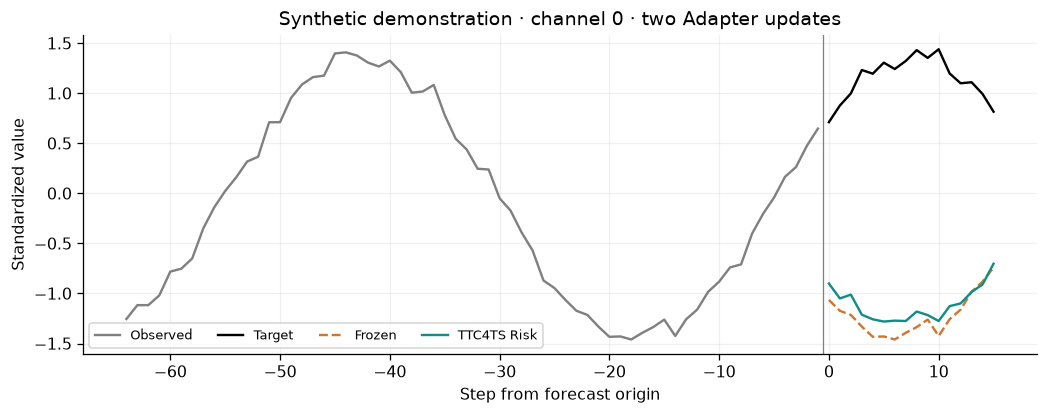

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout='constrained')
ax.plot(range(-context, 0), data[origin-context:origin, 0], color='gray', label='Observed')
ax.plot(range(horizon), target[:, 0], color='black', label='Target')
ax.plot(range(horizon), frozen[:, 0], '--', color='#ce7731', label='Frozen')
ax.plot(range(horizon), result.prediction[0, :, 0], color='#138c85', label='TTC4TS Risk')
ax.axvline(-.5, color='gray', lw=.8); ax.set(xlabel='Step from forecast origin', ylabel='Standardized value',
    title='Synthetic demonstration · channel 0 · two Adapter updates')
ax.legend(ncol=4, fontsize=8); plt.show()


This verifies shapes, convex weights, frozen state, and the deployment interface. It does
not establish superiority or calibrated uncertainty. Use notebook 01 for measured comparisons.
